# 04 — EMT-TF Expression · Raghavan et al. 2021 (PDAC)
The EMT-TF step is unconditional and is the **last** notebook (renumbered to 04 for the non-branching GO chain: 01 preprocessing, 02 manifold, 03 signatures, 04 expression). Score a widened mesenchymal-TF panel — Snail/Zeb/Twist **plus** the FOXC and PRRX families (VIM is a marker, not a TF, and is excluded) — gated on **detectable expression**, and overlay the two most informative factors as categorical thresholded-expresser layers on the grey manifold (house style).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load signatures manifold (carries the house layout + pseudotime)
Per §6 the expression step reads the processed data; here the signatures h5ad is used because it carries the pseudotime and `X_umap_lin` needed to place the factors on the developmental axis (same cells, same manifold).

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 7168 | pseudotime range 0.0 -> 8.93


### Score the widened EMT-TF panel, gated on detection
For each TF: detection fraction, mean expression in the early (root) vs late (terminus) pseudotime thirds, and the Spearman correlation with pseudotime. Pick the most root-loaded and most terminus-loaded factors among those above a 3% detection floor.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3),
                 round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 FOXC1      0.258       0.208      0.111    -0.195    EARLY(root)
 PRRX2      0.044       0.031      0.011    -0.118    EARLY(root)
  ZEB1      0.081       0.059      0.056    -0.073    EARLY(root)
 SNAI2      0.084       0.037      0.036    -0.048    EARLY(root)
 SNAI1      0.013       0.007      0.007    -0.032 LATE(terminus)
 PRRX1      0.005       0.002      0.003    -0.012 LATE(terminus)
TWIST1      0.005       0.001      0.004    -0.005 LATE(terminus)
  ZEB2      0.068       0.032      0.094     0.085 LATE(terminus)

derived pair: FOXC1 (early/root) <-> ZEB2 (late/terminus)


### Deliverable figure `expression.pdf` — categorical thresholded-expresser overlay
Grey manifold underneath; each chosen TF drawn as the cells above the upper quartile of its non-zero expression, in a fixed colour. House (3.5, 1.5) aspect on the shared orientation.

overlay thresholds (upper quartile among expressers): {'FOXC1': 0.817, 'ZEB2': 0.966} | cells shown: {'FOXC1': 462, 'ZEB2': 122}
FOXC1: 25.8% expressing; 462 shown (upper quartile), mean pseudotime of shown cells = 0.44 (all cells = 0.48)
ZEB2: 6.8% expressing; 122 shown (upper quartile), mean pseudotime of shown cells = 0.84 (all cells = 0.48)
shown-cell pseudotime separation (FOXC1 vs ZEB2) = 0.40
saved expression.pdf


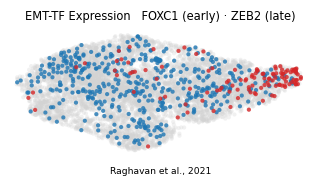

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Raghavan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
sep = abs(tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean())
print(f'shown-cell pseudotime separation ({early_tf} vs {late_tf}) = {sep:.2f}')
print('saved expression.pdf')